In [1]:
import numpy as np
import struct
import matplotlib.pyplot as plt

```
label_dict = { 0 : [idx_0_0,idx_0_1,...],
               1 : [idx_1_0,idx_1,0,...]
             }
             
             if we do a f.seek(idx_0_0 + 8) & f.read(1), we will get same label from the
             binary file
             
             We need to build something similar seek logic to read the image file
             
             How we read the image.
             From the idx you get, use below
             f.seek((idx * 28 * 28) + 16)
             img = [struct.unpack('B',f.read(1) for x in range(28*28)]
             img = np.array(img).reshape(28,28)
             plt.imshow(img,cmap="gray")
```

In [2]:
def get_label_dict(f_obj):
    label_dict = label_dict = {x : list() for x in range(10)}
    mg_n = struct.unpack('>i',f_obj.read(4))[0]
    n_labels = struct.unpack('>i',f_obj.read(4))[0]

    for idx in range(n_labels):
        l = struct.unpack('B',f_obj.read(1))[0]
        label_dict[l].append(idx)
    
    return label_dict

In [3]:
def get_image(f_obj, idx, n_rows = 28, n_cols = 28, initial_offset = 16):
    f_obj.seek((idx * n_rows * n_cols) + initial_offset)
    img = [ struct.unpack('B',f_obj.read(1)) for x in range(n_rows*n_cols)]
    return np.array(img).reshape(n_rows,n_cols)

In [4]:
def get_spacing(n_digits, image_width, min_spacing, max_spacing, per_image_width=28):
    min_size = n_digits * per_image_width
    blank_space = image_width - min_size
    
    # This is for edge to plotting #
    #cal_spacing = blank_space // (n_digits - 1)
    
    # This is for evenly spaced plotting, even at start and beginning
    cal_spacing = blank_space // (n_digits + 1)
    if cal_spacing < min_spacing or cal_spacing > max_spacing:
        raise ValueError("image_width : %d(px), min_spacing : %d(px) & max_spacing : %d(px) is not optimum for n_digits : %d" \
                         %(image_width,min_spacing,max_spacing,n_digits))
    return cal_spacing

In [5]:
label_file = open("data/t10k-labels-idx1-ubyte","rb")

In [6]:
label_dict = get_label_dict(label_file)
label_file.close()

In [7]:
n_rows = 28
n_rows = 28

In [10]:
def create_digit_sequence(number, image_width, min_spacing, max_spacing):
    try:
        number_list = [int(x) for x in number]
        image = np.zeros((n_rows,image_width))
        spacing = get_spacing(len(number_list),image_width,min_spacing,max_spacing)
        with open("data/t10k-images-idx3-ubyte","rb") as image_file:
            for idx, num in enumerate(number_list):
                image_idx = np.random.choice(label_dict[num])
                num_image = get_image(image_file,image_idx)
                # This is for edge to plotting #
                #s_w_px = (idx * spacing) + (idx * num_image.shape[1])
                
                # This is for evenly spaced plotting, even at start and beginning
                s_w_px = ((idx+1) * spacing) + (idx * num_image.shape[1])
                image[:,s_w_px:s_w_px + num_image.shape[1]] = num_image
        return image
    except Exception as e:
        raise e

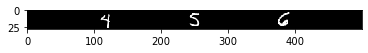

In [20]:
plt.imshow(create_digit_sequence("456",image_width=500,min_spacing=1,max_spacing=200),cmap="gray")
plt.show()